1. Моделирование 1000 событий для E = 1.0 МэВ...


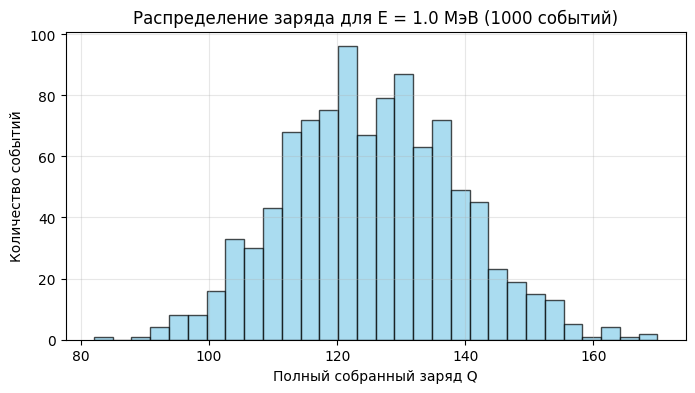

Средний заряд: 125.3 ± 13.3
Относительная ширина: 0.106

2. Исследование зависимости ширины от энергии...


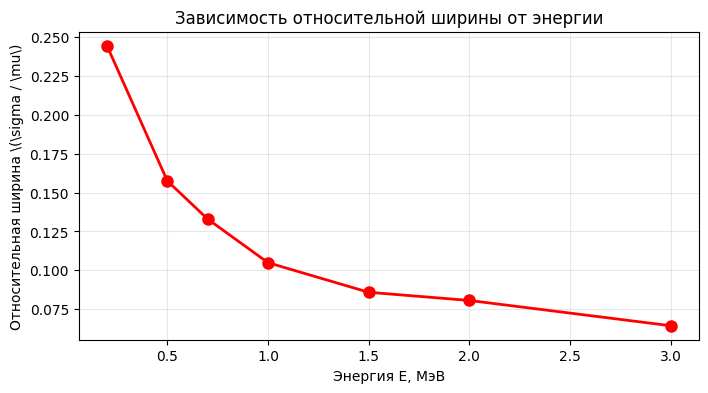

3. Моделирование со сдвинутым источником (Z = 1 м)...
Средний заряд (центр): 125.3
Средний заряд (сдвиг): 5.7
Изменение среднего: 95.4%


In [3]:
import numpy as np
import matplotlib.pyplot as plt

class Detector:
    def __init__(self, R, r, N):
        self.R = R
        self.r = r
        self.N = N
        self.positions = self._place_pmt()

    def _place_pmt(self):
        points = []
        while len(points) < self.N:
            p = np.random.uniform(-1, 1, size=3)
            length = np.linalg.norm(p)
            if 0 < length <= 1:
                points.append(p / length * self.R)
        return np.array(points)


def simulate_event(E, det, source_pos=(0.0, 0.0, 0.0), Y=10000, a=0.5):
    N_photons = int(E * Y)
    
    phi = np.random.uniform(0, 2 * np.pi, N_photons)
    cos_theta = np.random.uniform(-1, 1, N_photons)
    sin_theta = np.sqrt(1 - cos_theta**2)
    
    x = sin_theta * np.cos(phi)
    y = sin_theta * np.sin(phi)
    z = cos_theta
    directions = np.column_stack((x, y, z))
    hit_points = directions * det.R + np.array(source_pos)
    
    total_electrons = 0
    
    for center in det.positions:
        dist = np.linalg.norm(hit_points - center, axis=1)
        num_hits = np.sum(dist <= det.r)
        if num_hits > 0:
            total_electrons += np.random.poisson(a * num_hits)
    return total_electrons

det = Detector(R=2.0, r=0.1, N=40)

print("1. Моделирование 1000 событий для E = 1.0 МэВ...")
E = 1.0
N_events = 1000
charges_1MeV = [simulate_event(E, det) for _ in range(N_events)]

plt.figure(figsize=(8, 4))
plt.hist(charges_1MeV, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
plt.xlabel('Полный собранный заряд Q')
plt.ylabel('Количество событий')
plt.title(f'Распределение заряда для E = {E} МэВ (1000 событий)')
plt.grid(alpha=0.3)
plt.show()

mean_1MeV = np.mean(charges_1MeV)
std_1MeV = np.std(charges_1MeV)
print(f"Средний заряд: {mean_1MeV:.1f} ± {std_1MeV:.1f}")
print(f"Относительная ширина: {std_1MeV / mean_1MeV:.3f}\n")

print("2. Исследование зависимости ширины от энергии...")
energies = [0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]
rel_widths = []

for E in energies:
    charges = [simulate_event(E, det) for _ in range(1000)]
    rel_widths.append(np.std(charges) / np.mean(charges))

plt.figure(figsize=(8, 4))
plt.plot(energies, rel_widths, 'o-', color='red', linewidth=2, markersize=8)
plt.xlabel('Энергия E, МэВ')
plt.ylabel(r'Относительная ширина \(\sigma / \mu\)')
plt.title('Зависимость относительной ширины от энергии')
plt.grid(alpha=0.3)
plt.show()

print("3. Моделирование со сдвинутым источником (Z = 1 м)...")
source_pos = (0.0, 0.0, 1.0)
charges_shifted = [simulate_event(1.0, det, source_pos=source_pos) for _ in range(1000)]

mean_shifted = np.mean(charges_shifted)

print(f"Средний заряд (центр): {mean_1MeV:.1f}")
print(f"Средний заряд (сдвиг): {mean_shifted:.1f}")
print(f"Изменение среднего: {abs(mean_shifted - mean_1MeV) / mean_1MeV * 100:.1f}%")